# Data Augmentation for Medical Insurance Price Prediction
**Dataset:** [Kaggle — Medical Insurance Price Prediction](https://www.kaggle.com/datasets/harishkumardatalab/medical-insurance-price-prediction)

**Question:** if we only have a few real rows, does adding *synthetic* rows help a model predict `charges`?

We compare three augmentation methods against training on real data only:

| Method | Idea |
|---|---|
| **Noise (jitter)** | Copy real rows and add small random noise to `age`, `bmi`, `charges` |
| **Gaussian Copula** (SDV) | Statistical model of each column's distribution and their correlations |
| **CTGAN** (SDV) | A GAN for tables: a generator creates rows, a discriminator tries to tell them from real ones |

**Rule:** synthetic data is created **only from the training set**. The test set is always 100% real and never seen by the generators.

## 1. Setup

In [1]:
# %pip install sdv kagglehub   # run once if needed
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from sdv.metadata import Metadata
from sdv.single_table import GaussianCopulaSynthesizer, CTGANSynthesizer
from sdv.evaluation import evaluate_quality
import warnings
warnings.filterwarnings("ignore")
SEED = 42

c:\Users\USUARIO\OneDrive - INSTITUCION UNIVERSITARIA SALAZAR Y HERRERA\Escritorio\knowledge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load data

In [2]:
path = kagglehub.dataset_download("harishkumardatalab/medical-insurance-price-prediction")
print("Path to dataset files:", path)
df = pd.read_csv(os.path.join(path, "Medical_insurance.csv"))
print("Shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())
df.head()

Path to dataset files: C:\Users\USUARIO\.cache\kagglehub\datasets\harishkumardatalab\medical-insurance-price-prediction\versions\1
Shape: (2772, 7)
Exact duplicate rows: 1435


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Duplicates
About half of the rows in this Kaggle file are exact copies. If we keep them, the same row can end up in both train and test, and the score looks better than it really is (**data leakage**). So we drop them first.

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

Shape after dropping duplicates: (1337, 7)


## 3. Train / test split and a small training set
Augmentation is meant for when real data is scarce, so we simulate that with **200** real training rows.

In [4]:
train, test = train_test_split(df, test_size=0.25, random_state=SEED, stratify=df["smoker"])
small = train.sample(200, random_state=SEED).reset_index(drop=True)
N_SYN = 800  # synthetic rows to add
print(f"Full train: {len(train)}  |  small train: {len(small)}  |  test: {len(test)}")

Full train: 1002  |  small train: 200  |  test: 335


## 4. Model and evaluation function
The same Random Forest is trained on each version of the training data and always scored on the same real test set.

In [5]:
def evaluate(train_df):
    X = pd.get_dummies(train_df.drop(columns="charges"), drop_first=True)
    X_test = pd.get_dummies(test.drop(columns="charges"), drop_first=True).reindex(columns=X.columns, fill_value=0)
    model = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED)
    model.fit(X, train_df["charges"])
    pred = model.predict(X_test)
    return {"R2": r2_score(test["charges"], pred), "MAE": mean_absolute_error(test["charges"], pred)}

## 5. Augmentation methods

### 5.1 Noise (jitter)

In [6]:
def jitter(data, n, seed=SEED):
    rng = np.random.default_rng(seed)
    out = data.sample(n, replace=True, random_state=seed).reset_index(drop=True)
    out["age"] = (out["age"] + rng.integers(-2, 3, n)).clip(18, 64)
    out["bmi"] = out["bmi"] * rng.normal(1, 0.03, n)
    out["charges"] = out["charges"] * rng.normal(1, 0.05, n)
    return out

syn_jitter = jitter(small, N_SYN)

### 5.2 Gaussian Copula and 5.3 CTGAN (SDV)
SDV 2.x takes each table as a dictionary `{table_name: DataFrame}`.

In [7]:
metadata = Metadata.detect_from_dataframes({"insurance": small})

def synthesize(synth_cls, **kwargs):
    synth = synth_cls(metadata, **kwargs)
    synth.fit({"insurance": small})
    out = synth.sample(N_SYN)
    return out["insurance"] if isinstance(out, dict) else out

syn_gc = synthesize(GaussianCopulaSynthesizer)
syn_ctgan = synthesize(CTGANSynthesizer, epochs=300)  # ~1 minute on CPU
syn_ctgan.head()

,age,sex,bmi,children,smoker,region,charges
0,54,male,28.506,3,yes,northwest,14325.95557
1,29,female,31.516,0,yes,northeast,10862.46843
2,43,female,30.276,0,no,northwest,1141.44510
3,42,male,29.255,1,no,northwest,1141.44510
4,52,male,49.651,3,yes,northwest,6520.58368


## 6. How realistic is the synthetic data?
SDV's quality score (0–1) compares column shapes and column pairs against the real data.

In [8]:
for name, syn in [("Jitter", syn_jitter), ("Gaussian Copula", syn_gc), ("CTGAN", syn_ctgan)]:
    q = evaluate_quality({"insurance": small}, {"insurance": syn}, metadata, verbose=False).get_score()
    print(f"{name:16s} quality: {q:.3f}")

Jitter           quality: 0.937


Gaussian Copula  quality: 0.813


CTGAN            quality: 0.801


The key pattern in this dataset: **smokers with high BMI pay much more**. Does the synthetic data keep it?

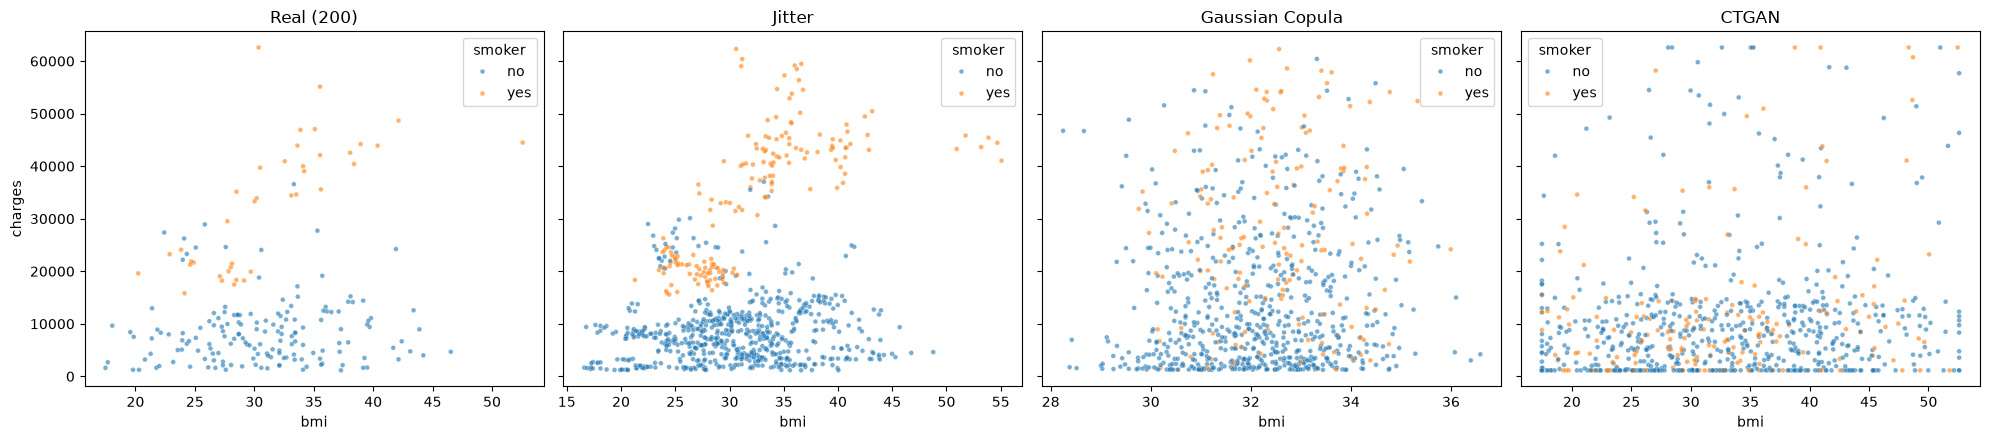

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, (name, d) in zip(axes, [("Real (200)", small), ("Jitter", syn_jitter), ("Gaussian Copula", syn_gc), ("CTGAN", syn_ctgan)]):
    sns.scatterplot(data=d, x="bmi", y="charges", hue="smoker", hue_order=["no", "yes"], s=12, alpha=.6, ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 7. Results

In [10]:
results = {
    "Real 200 (baseline)": evaluate(small),
    "Real 200 + Jitter": evaluate(pd.concat([small, syn_jitter])),
    "Real 200 + Gaussian Copula": evaluate(pd.concat([small, syn_gc])),
    "Real 200 + CTGAN": evaluate(pd.concat([small, syn_ctgan])),
    "CTGAN only (no real rows)": evaluate(syn_ctgan),
    f"All real train ({len(train)}) — upper bound": evaluate(train),
}
res = pd.DataFrame(results).T.round({"R2": 3, "MAE": 0})
res

,R2,MAE
Real 200 (baseline),0.855,2905.0
Real 200 + Jitter,0.795,3308.0
Real 200 + Gaussian Copula,0.640,5312.0
Real 200 + CTGAN,0.277,7146.0
CTGAN only (no real rows),-0.083,9163.0
All real train (1002) — upper bound,0.875,2479.0


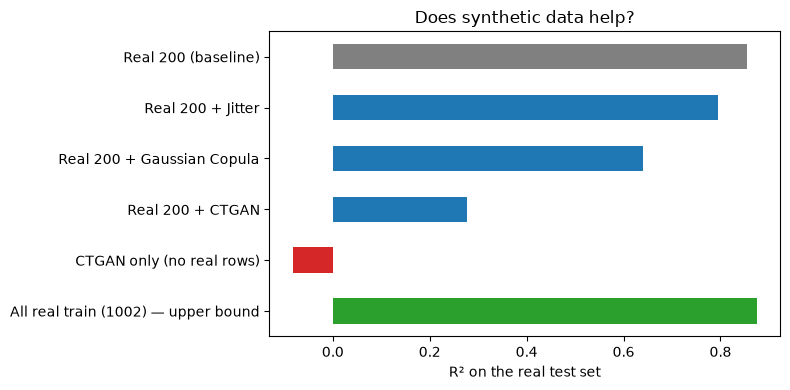

In [11]:
ax = res["R2"].plot.barh(figsize=(8, 4), color=["grey", "tab:blue", "tab:blue", "tab:blue", "tab:red", "tab:green"])
ax.invert_yaxis(); ax.set_xlabel("R² on the real test set"); ax.set_title("Does synthetic data help?")
plt.tight_layout(); plt.show()

## 8. Conclusions
Write your own reading of the table above; typical results with this setup:

- **Synthetic data from SDV did not help here — it hurt.** Gaussian Copula and CTGAN learn each column well but blur the **smoker × BMI** interaction that drives `charges`, so the model learns a weaker rule.
- **CTGAN needs more data than we gave it.** GANs are hungry: 200 rows and 300 epochs are not enough for the generator to learn the joint distribution. Training only on CTGAN rows is much worse than the baseline.
- **Jitter is the safest augmentation** because it stays close to real rows, but it adds little new information — a Random Forest already handles small variations.
- **More real data beats synthetic data:** the full real training set is the best result.
- **Where synthetic data *is* useful:** sharing data without exposing real patients (privacy), testing pipelines, and balancing rare classes in classification — not as a free boost in accuracy.
- Data quality matters first: half the Kaggle file was duplicates, which would have inflated every score.